In [390]:
import numpy as np
import scipy as sp
from scipy.optimize import root
import matplotlib.pyplot as plt
import CoolProp.CoolProp as CP
import thermo as thermo
import copy

In [275]:
# --- MATERIAL PROPERTY FUNCTIONS (reuse from previous project) ---
def Sn_rho(temp):
    # liquid Tin density, Stankus
    return 6982.2 - 0.75643 * (temp - 505) + 1.074e-4 * (temp - 505) ** 2 - 2.194e-8 * (temp - 505) ** 3

def Sn_mu(temp):
    # liquid Tin viscosity [Pas]
    return 3.908e-4 * np.exp(790.7 / temp)

def Sn_cp(temp):
    # Tin cp [J/kgK] (constant for simplicity)
    return 300

def Sn_tcx(temp):
    # Tin thermal conductivity [W/mK]
    return 13.9 + 0.02868 * temp

def Sn_Pr(temp):
    return Sn_cp(temp) * Sn_mu(temp) / Sn_tcx(temp)

def gr_emis(temp):
    # graphite emissivity vs. temp (simple model)
    return 0.679 + 6e-5 * temp

def gr_tcx(temp: float) -> float:
    """
    Calculate the thermal conductivity of graphite as a function of temperature.
    
    Parameters:
    temp (float): Temperature (K).
    
    Returns:
    float: Thermal conductivity of graphite (W/mK).
    """
    tcx_arr = np.array([[20,	115],
    [200,	100],
    [400,	85],
    [600,	73],
    [800,	62],
    [1000,	54],
    [1200,	49],
    [1400,	45],
    [1600,	42],
    [1800,	40],
    [2000,	39],
    [2200,	37],
    [2400,	34]]
                     )
    return np.interp(1100,tcx_arr[:,0],tcx_arr[:,1])

def storage_rho(temp):
    #storage graphite density
    #return 1743
    return 1450

def storage_cp(temp):
    #storage graphite specific heat
    #replaced with fixed cp until better enthalpy handling implemented
    cp_arr= np.array([1.27, 1.92, 1.99, 2.13])
    temp_C = np.array([300, 750, 1200, 1995])
    temp_C = np.append(temp_C,2400)
    cp_arr = np.append(cp_arr, 2.13)
    temp_C_interp = temp - 273.15
    # Extrapolate up to 2400°C
    if temp_C_interp > 2400:
        temp_C_interp = 2400
    return 2000   
    #return np.interp(temp_C_interp, temp_C, cp_arr) * 1000

def storage_tcx(temp):
    #storage graphite conductivity
    temp_C = np.array([300, 750, 1200, 1995])
    conductivity = np.array([31.5, 28.7, 24.8, 23.1])
    temp_C_interp = temp - 273.15
    temp_C = np.append(temp_C,2400)
    conductivity = np.append(conductivity, conductivity[-1] + (conductivity[-1] - conductivity[-2]) / (temp_C[-2] - temp_C[-3]) * (temp_C[-1] - temp_C[-2]))
        # Extrapolate up to 2400°C
    if temp_C_interp > 2400:
        temp_C_interp = 2400
    return 15
    #return np.interp(temp_C_interp, temp_C, conductivity)

def CircPipeFF(Re, D_h, rough):
    if (Re < 2300):
        return 64 / Re
    else:
        return (-2 * np.log10(2 * rough / (7.54 * D_h) - 5.02 / Re * np.log10(2*rough / (7.54 * D_h) + 13 / Re))) ** (-2)

def CircPipeNu(Re, ff, Pr):
    if (Re < 2300):
        return 4.36
    else:
        return 5.31 + 0.221 * (Re * Pr) ** 0.8174

def RprimeCondCyl(D_in, D_out, k_wall):
    #def cylindrical wall conduction thermal resistance [K/Wm]
    return np.log(D_out / D_in) / (2 * np.pi * k_wall)

def RCondWall(L, A_c, k_wall):
    #define planar conduction thermal resistance [K/W]
    return L / (k_wall * A_c)

def RprimeConvCyl(Nu, k_fluid, D):
    #define convection thermal resistance for a fluid in a pipe [K/Wm]
    h_bar = Nu * k_fluid / D
    per = np.pi * D
    return 1 / (h_bar * per)

def RConvWall(Nu, L, A_c, k_fluid):
    #def convection thermal resistance on a planar wall [K/W]
    #L is the characteristic length, hydraulic diameter for internal flows
    h_bar = Nu * k_fluid / L
    return 1 / (h_bar * A_c)

def Rrad(T_sur, T_s, A_s, VF, emis):
    #def exact radiation thermal resistance [K/W]
    return 1 / (A_s * emis * (T_s ** 2 + T_sur ** 2) * (T_sur + T_s) * sp.constants.sigma)

def Rrad_2surfaces(T_1, T_2, A_1, A_2, emis_1, emis_2, VF_12):
    #def radiation thermal resistance between 2 grey bodies [K/W]
    R_rad = ((1 - emis_1) / (A_1 * emis_1) + 1 / (A_1 * VF_12) + (1 - emis_2) / 
             (A_2 * emis_2)) / ((T_1 ** 2 + T_2 ** 2) * (T_1 + T_2) * sp.constants.sigma)
    return R_rad

In [276]:
class Fluid:
    def __init__(self, temperature: float, pressure: float, flow_rate: float):
        """
        Initialize the Fluid object with its properties.
        
        Parameters:
        temperature (float): Temperature of the fluid (K).
        pressure (float): Pressure of the fluid (Pa).
        flow_rate (float): Flow rate of the fluid (kg/s).
        """
        self.temperature = temperature
        self.pressure = pressure
        self.flow_rate = flow_rate
        
class Pipe:
    def __init__(self, OD: float, length: float, wall_thickness: float, roughness: float, th_ins: float):
        """
        Initialize the Pipe object with its physical properties.
        
        Parameters:
        diameter (float): Inner diameter of the pipe (meters).
        length (float): Length of the pipe (meters).
        wall_thickness (float): Wall thickness of the pipe (meters).
        roughness (float): Surface roughness of the pipe (meters).
        th_ins (float): Insulation thickness
        """
        self.OD = float(OD)
        self.length = float(length)
        self.wall_thickness = float(wall_thickness)
        self.roughness = float(roughness)
        self.ID = self.OD - 2 * self.wall_thickness
        self.A_s = np.pi * self.OD * self.length
        self.A_c = self.OD * self.length
        self.A_in = np.pi * self.ID ** 2 / 4
        self.th_ins = th_ins
        self.volume = self.length * np.pi * self.ID ** 2 / 4

    def pressure_drop(self, fluid: Fluid) -> float:
        """
        Calculate the pressure drop of the pipe using the Darcy-Weisbach equation.
        
        Parameters:
        fluid (Fluid): Fluid object containing the flow conditions.
        
        Returns:
        float: Pressure drop (Pa).
        """
        mdot = fluid.flow_rate
        fluid_viscosity = Sn_mu(fluid.temperature)
        fluid_density = Sn_rho(fluid.temperature)
        # Calculate velocity
        Vdot = mdot / fluid_density
        velocity = Vdot / (np.pi * (self.ID / 2) ** 2)
        # Calculate Reynolds number
        reynolds_number = 4 * mdot / (np.pi * fluid_viscosity * self.ID)
        #return circular pipe friction factor (turbulent: Zigrang and Sylvester)
        friction_factor = CircPipeFF(reynolds_number, self.ID, self.roughness)
        # Calculate pressure drop
        pressure_drop = 0.5 * fluid_density * velocity ** 2 * friction_factor * self.length / self.ID
        return pressure_drop

    def heat_loss(self, fluid: Fluid, T_sur: float, num_shells: int = 10, tol: float = 1e-3, max_iter: int = 100) -> tuple:
        """
        Calculate the heat loss of the pipe to ambient.
        
        Parameters:
        fluid (Fluid): Fluid object containing the flow conditions.
        T_sur (float): Surrounding temperature (K).
        num_shells (int): Number of discretized shells for the insulation.
        tol (float): Tolerance for convergence.
        max_iter (int): Maximum number of iterations.
        
        Returns:
        tuple: Heat loss (W) and Fluid object containing the outlet conditions.
        """
        mdot = fluid.flow_rate
        T_in = fluid.temperature
        fluid_viscosity = Sn_mu(T_in)
        fluid_density = Sn_rho(T_in)
        fluid_cp = Sn_cp(T_in)
        fluid_tcx = Sn_tcx(T_in)
        h_out = 100 #pipe surface heat transfer coefficient estimate, W/m^2K
        r_inner = self.OD / 2
        r_outer = r_inner + self.th_ins
        dr = (r_outer - r_inner) / num_shells

        reynolds_number = 4 * mdot / (np.pi * fluid_viscosity * self.ID)
        friction_factor = CircPipeFF(reynolds_number, self.ID, self.roughness)
        Nu_pipe = CircPipeNu(reynolds_number, friction_factor, Sn_Pr(T_in))  # Nusselt number
        R_cond_pipe = RprimeCondCyl(self.ID, self.OD, gr_tcx(T_in)) / self.length  # Conduction resistance
        R_conv_in = RprimeConvCyl(Nu_pipe, fluid_tcx, self.ID) / self.length  # Convection resistance
        R_conv_out = 1 / (h_out * np.pi * (self.OD + 2 * self.th_ins) * self.length)
        # Initial temperature distribution (linear guess)
        T_shells = np.linspace(T_in, T_sur + (T_in - T_sur) / num_shells, num_shells)
        
        for iteration in range(max_iter):
            R_shells = temperatures = np.zeros(num_shells)
            R_tin_to_shells = temperatures = np.zeros(num_shells)
            T_old = np.copy(T_shells)
            R_cond_ins = 0
            for j in range(num_shells):
                r_i = r_inner + j * dr
                R_shells[j] = RprimeCondCyl(2 * r_i, 2 * (r_i + dr), ins_tcx(T_shells[j])) / self.length

            R_cond_ins = sum(R_shells)
            R_tot = R_cond_pipe + R_cond_ins + R_conv_in + R_conv_out
            Q_loss = (T_in - T_sur) / R_tot    
            for j in range(num_shells):
                R_tin_to_shells[j] = R_conv_in + R_cond_pipe + sum(R_shells[0:j])
                T_shells[j] = T_in - Q_loss * R_tin_to_shells[j]
                
            # Check for convergence
            if np.max(np.abs(T_shells - T_old)) < tol:
                break

        T_out = T_in - Q_loss / (mdot * fluid_cp)
        return Q_loss, Fluid(T_out, fluid.pressure, mdot), T_shells
        
class GraphiteBlock:
    def __init__(self, initial_temp_distribution: np.ndarray, inner_radius: float, outer_radius: float, length: float, th_ins: float):
        """
        Initialize the GraphiteBlock object with its physical properties.
        
        Parameters:
        initial_temp_distribution (array): Initial temperature distribution in the block (K).
        inner_radius (float): Inner radius of the block (meters).
        outer_radius (float): Outer radius of the block (meters).
        length (float): Length of the block (meters).
        """
        self.temp_dist = initial_temp_distribution.astype(float)
        self.rad_in = float(inner_radius)
        self.rad_out = float(outer_radius)
        self.length = float(length)
        self.th_ins = float(th_ins)

class PowerStick:
    def __init__(self, axial_steps: int, width: float, height: float, cooling_temp: float, panel_efficiency: float, f_bare: float, f_active: float, emissivity_table: list = None):
        """
        Initialize the PowerStick object with its physical properties.
        
        Parameters:
        width (float): Width of the power stick (m).
        height (float): Height of the power stick (m).
        cooling_temp (float): Cooling temperature to maintain the power stick (K).
        panel_efficiency (float): Percent of absorbed light above bandgap converted to electricity
        f_bare (float): Fraction of powerstick area not covered by SNGC
        f_active (float): Fraction of SNGC-covered area that produces electricity
        emissivity_table (list): List of tuples containing wavelength ranges and corresponding emissivities.
        """
        self.num_ax_steps = axial_steps
        self.width = width
        self.height = height
        self.height_step = self.height / self.num_ax_steps
        self.A_step = 4 * self.height_step * self.width
        self.cooling_temp = cooling_temp
        self.emissivity_table = emissivity_table if emissivity_table is not None else []
        self.panel_efficiency = panel_efficiency
        self.f_bare = f_bare
        self.f_active = f_active

    def update_emissivity_table(self, new_emissivity_table):
        self.emissivity_table = new_emissivity_table

    def generate_electricity_step(self, T_emitter: float, view_factor: float, efficiency: float) -> tuple:
        """
        Calculate the electricity generated by the power stick based on incident energy.
        
        Parameters:
        T_emitter (float): Temperature of the emitter surface (K).
        emitter_emissivity (float): Emissivity of the emitter surface.
        view_factor (float): View factor between the emitter and the powerstick.
        efficiency (float): Efficiency of converting absorbed heat to electricity.
        
        Returns:
        tuple: Electricity generated (W) and waste heat to be removed by the cooling system (W).
        """
        incident_energy_bins, emissivity_bins, incident_photon_bins = self.incident_energy(T_emitter, view_factor)
        
        absorbed_energy_below_bandgap = 0
        absorbed_energy_above_bandgap = 0
        absorbed_energy_bare = 0
        absorbed_energy_inactive = 0
        elec_flux = 0
        e_charge = 1.60218e-19 #electron charge, Coulombs
        P_collect = 1 #probability of photon above bandgap being absorbed
        V_panel = 1 #voltage on panel, update
        
        for i, (wavelength_range, emis_active, emis_bare, emis_inactive) in enumerate(self.emissivity_table):
            avg_panel_emis = self.f_bare * emis_bare + (1 - self.f_bare) * self.f_active * emis_active + (1 - self.f_bare) * (1- self.f_active) * emis_inactive
            absorbed_energy_bare += incident_energy_bins[wavelength_range] * self.f_bare * emis_bare / avg_panel_emis
            absorbed_energy_inactive += incident_energy_bins[wavelength_range] * (1 - self.f_bare) * (1 - self.f_active) * emis_inactive / avg_panel_emis
            if i == 0:  # First bin is below the bandgap
                absorbed_energy_below_bandgap += incident_energy_bins[wavelength_range] * (1 - self.f_bare) * self.f_active * emis_active / avg_panel_emis
                elec_flux += incident_photon_bins[wavelength_range] * P_collect * e_charge * V_panel# * emis_active
            elif i == 1:  # Second bin is above the bandgap
                absorbed_energy_above_bandgap += incident_energy_bins[wavelength_range] * (1 - self.f_bare) * self.f_active * emis_active / avg_panel_emis

        absorbed_heat = (absorbed_energy_below_bandgap + absorbed_energy_above_bandgap + absorbed_energy_bare + absorbed_energy_inactive) * self.A_step  # Total absorbed heat (W)
        electricity = absorbed_energy_below_bandgap * self.A_step * self.panel_efficiency
        electricity2 = elec_flux * self.A_step
        waste_heat = absorbed_heat - electricity
        return electricity, waste_heat

    def incident_energy(self, T_emitter: float, view_factor: float) -> tuple:
        """
        Calculate the total amount of incident energy on the powerstick surface in each energy bin based on the blackbody spectrum.
        
        Parameters:
        T_emitter (float): Temperature of the emitter surface (K).
        emitter_emissivity (float): Emissivity of the emitter surface.
        view_factor (float): View factor between the emitter and the powerstick.
        
        Returns:
        tuple: Total amount of incident energy in each energy bin (W/m^2), and corresponding powerstick emissivities.
        """
        # Constants
        h = 6.62607015e-34  # Planck constant (J·s)
        c = 2.99792458e8    # Speed of light (m/s)
        k = 1.380649e-23    # Boltzmann constant (J/K)
        
        # Initialize dictionaries to store incident energy and powerstick emissivity for each bin
        incident_energy_bins = {range_: 0.0 for range_, _, _, _ in self.emissivity_table}
        incident_photon_bins = {range_: 0.0 for range_, _, _, _ in self.emissivity_table}
        emissivity_bins = {range_: emissivity for range_, emissivity, _, _ in self.emissivity_table}
        
        # Wavelength range (microns)
        wavelength_min = self.emissivity_table[0][0][0]
        wavelength_max = self.emissivity_table[1][0][1]
        band_gap = self.emissivity_table[0][0][1]
        n_bins = 500
        
        wavelengths = np.logspace(np.log10(wavelength_min),np.log10(wavelength_max),n_bins)
        wavelengths_m = wavelengths * 1e-6  # Convert to meters
        # Planck's law (Watts / square meter / meter)
        spectral_radiance = np.pi * (2 * h * c**2) / (wavelengths_m**5) * (1 / (np.expm1((h * c) / (wavelengths_m * k * T_emitter))))
        spectral_count = spectral_radiance / (h * c / wavelengths_m)
        
        # Calculate incident energy
        for i, wavelength in enumerate(wavelengths):
            emitter_emis = gr_emis(T_emitter)
            if wavelength < band_gap:
                band_width = wavelengths_m[i+1] - wavelengths_m[i]
            else:
                band_width = wavelengths_m[i] - wavelengths_m[i-1]
                
            for (wavelength_range, emis_active, emis_bare, emis_inactive) in self.emissivity_table:
                if wavelength_range[0] <= wavelength < wavelength_range[1]:
                    avg_panel_emis = self.f_bare * emis_bare + (1 - self.f_bare) * self.f_active * emis_active + (1 - self.f_bare) * (1- self.f_active) * emis_inactive
                    incident_energy_bins[tuple(wavelength_range)] += (
                        spectral_radiance[i] * (band_width) / (view_factor * 
                                    (1 - emitter_emis) / emitter_emis + 1 + (1 - avg_panel_emis) / avg_panel_emis)
                    )
                    incident_photon_bins[tuple(wavelength_range)] += spectral_count[i]
                    break

        return incident_energy_bins, emissivity_bins, incident_photon_bins

class Emitter:
    def __init__(self, width: float, height: float, wall_thickness: float, N_pipes: int, pipe: Pipe):
        """
        Initialize the Emitter object with its physical properties.
        
        Parameters:
        width (float): Width of the emitter (m).
        height (float): Height of the emitter (m).
        wall_thickness (float): Thickness of the graphite wall (m).
        pipe (RectangularPipe): Rectangular pipe object liquid tin channels
        """
        self.width = width
        self.height = height
        self.wall_thickness = wall_thickness
        self.N_pipes = N_pipes
        self.pipe = pipe

    def R_tin_to_surf(self, fluid: Fluid, T_graphite: float):
        """
        Calculate thermal resistance per meter between liquid tin for given guess values of the graphite and tin temperatures
        
        Parameters:
        fluid (Fluid): Fluid object containing the flow conditions.
        T_graphite (float): Graphite surface temperature guess (K)
        """
        mdot = fluid.flow_rate
        T_tin = fluid.temperature
        A_emitter = 4 * self.width  #emitter area per meter length
        u = mdot / (self.N_pipes * Sn_rho(T_tin) * self.pipe.A_in) #mdot is 1/4 total mdot b/c 4 rectangular channels per module
        Re = Sn_rho(T_tin) * u * self.pipe.ID / Sn_mu(T_tin)
        ff_pipe = CircPipeFF(Re, self.pipe.ID, self.pipe.roughness)
        Nu_pipe = CircPipeNu(Re, ff_pipe, Sn_Pr(T_tin))
        h_conv = Nu_pipe * Sn_tcx(T_tin) / self.pipe.ID
        R_conv = 1 / (h_conv * A_emitter)
            
        # Conduction resistance across graphite wall
        R_cond_graphite = self.wall_thickness / (gr_tcx(T_graphite) * A_emitter)
        R_tot = R_conv + R_cond_graphite
        return R_tot, R_conv, R_cond_graphite


In [524]:
class StorageModule:
    def __init__(self, N_pipes: int, Pipe: Pipe, Block: GraphiteBlock, num_ax_segments: int, num_rad_segments: int, bypass_range: list):
        """
        Initialize the StorageModule object with its physical properties.
        
        Parameters:
        N_pipes (int): Number of pipes in the storage module.
        Pipe (Pipe): Pipe object representing the physical properties of the pipe.
        Block (GraphiteBlock): GraphiteBlock object representing the physical properties of the storage block.
        num_ax_segments (int): Number of axial segments in the storage block.
        num_rad_segments (int): Number of radial segments in the storage block.
        bypass_range (list): Lower and upper bypass ratio limits
        """
        self.pipe = Pipe
        self.N_pipes = N_pipes
        self.block = Block
        self.num_ax_segments = num_ax_segments
        self.segment_length = self.pipe.length / num_ax_segments
        self.num_rad_segments = num_rad_segments
        self.bypass_range = bypass_range

    def pressure_drop(self, fluid: Fluid) -> float:
        # If there are N_pipes, compute total drop for parallel flow
        mdot_per = fluid.flow_rate / self.N_pipes
        # Use block inlet pipe for now
        dp_pipe = self.pipe.pressure_drop(Fluid(fluid.temperature, fluid.pressure, mdot_per))
        # If more hydraulic losses (manifolds, block internals), sum here
        # dp_total = dp_pipe + dp_manifold + ...
        return dp_pipe # + other losses as needed
        
    def heat_transfer_rate(self, fluid: Fluid, T_block_surface: float) -> float:
        """
        Calculate the heat transfer rate from the pipe segment to the storage block surface.
        
        Parameters:
        fluid (Fluid): Fluid object containing the inlet conditions to each block.
        T_block_surface (float): Temperature of the storage block surface (K).
        
        Returns:
        float: Radiative heat transfer rate (W).
        """
        T_tin = fluid.temperature
        mdot = fluid.flow_rate
        T_block_surface = float(T_block_surface)
        VF = 1.0 # Assuming direct view factor
            
        A_pipe = np.pi * self.pipe.OD * self.segment_length
        A_block_surface = np.pi * self.block.rad_in * 2 * self.segment_length
        Re = 4 * mdot / (np.pi * Sn_mu(T_tin) * self.pipe.ID)  # Reynolds number
        ff_pipe = CircPipeFF(Re, self.pipe.ID, self.pipe.roughness)  # Darcy friction factor
        Nu_pipe = CircPipeNu(Re, ff_pipe, Sn_Pr(T_tin))  # Nusselt number
        R_cond = RprimeCondCyl(self.pipe.ID, self.pipe.OD, gr_tcx(T_tin)) / self.segment_length  # Conduction resistance
        R_conv = RprimeConvCyl(Nu_pipe, Sn_tcx(T_tin), self.pipe.ID) / self.segment_length  # Convection resistance
        
        T_pipe_surface = T_tin
        
        #Effectiveness-NTU method for calculating heat transfer from block to tin
        C_min = fluid.flow_rate * Sn_cp(fluid.temperature)
        
        for _ in range(100):  # Maximum 100 iterations
            emis_pipe = gr_emis(T_pipe_surface)
            emis_block = gr_emis(T_block_surface)
            R_rad = Rrad_2surfaces(T_pipe_surface, T_block_surface, A_pipe, A_block_surface, emis_pipe, emis_block, VF)  # Radiative resistance
            R_tot = R_cond + R_conv + R_rad  # Total resistance [K/W]
            UA = 1 / R_tot
            NTU = UA / C_min
            effectiveness = 1 - np.exp(-NTU) #single fluid HEX, rough approx of storage block
            Q_rad = effectiveness * C_min * (fluid.temperature - T_block_surface)
            T_pipe_surface_new = T_tin - Q_rad * (R_cond + R_conv)  # Update pipe surface temperature based on Q and resistances
            if abs(T_pipe_surface_new - T_pipe_surface) < 1e-2:  # Convergence criterion
                break
            
            T_pipe_surface = T_pipe_surface_new 
            
        return Q_rad

    def bypass_outlet_condition(self, storage_bypass_fraction, inlet_fluid):
        """Combine block bypass with the main flow, calculate mixed temp."""
        storage_in_main = copy.deepcopy(inlet_fluid)
        storage_in_bypass = copy.deepcopy(inlet_fluid)
        storage_in_main.flow_rate *= (1 - storage_bypass_fraction)
        storage_in_bypass.flow_rate *= storage_bypass_fraction

        storage_out_main, Q_store, Q_rad_dist, T_tin_ax_block = self.outlet_conditions(storage_in_main)
        storage_out_bypass = copy.deepcopy(storage_in_bypass)
        # Bypass fluid does not change temp!
        storage_out_temp = (storage_out_main.temperature * storage_out_main.flow_rate + storage_out_bypass.temperature
                            * storage_out_bypass.flow_rate) / inlet_fluid.flow_rate
        outlet_fluid = Fluid(storage_out_temp, storage_out_main.pressure, inlet_fluid.flow_rate)
        return outlet_fluid, Q_store, Q_rad_dist, T_tin_ax_block

    def optim_bypass_ratio(self, init_bypass_fraction, inlet_fluid, target_outlet_temp, abs_tol=1e-2, deriv_tol=1e-8, max_iterations=100):
        # find optimal bypass ratio using Newton-Raphson
        storage_bypass_fraction = init_bypass_fraction
        derivative = 1
        last_derivative = 2
        
        if inlet_fluid.temperature > target_outlet_temp: #skip calc if fluid coming in above target temp, know have to max bypass
            return self.bypass_range[1]
        else:
            storage_out_min, _, _, _ = self.bypass_outlet_condition(self.bypass_range[0], inlet_fluid)
            if storage_out_min.temperature < target_outlet_temp:
                return self.bypass_range[0]
            else:
                storage_out_max, _, _, _ = self.bypass_outlet_condition(self.bypass_range[1], inlet_fluid)
                #print("outlet temp at max bypass:", storage_out_max.temperature)
                if storage_out_max.temperature > target_outlet_temp:
                    return self.bypass_range[1]
            for _ in range(max_iterations):
                #limit bypass fraction to within bounds
                storage_bypass_fraction = min(self.bypass_range[1], max(self.bypass_range[0], storage_bypass_fraction))
                storage_out, _, _, _ = self.bypass_outlet_condition(storage_bypass_fraction, inlet_fluid)
                residual = storage_out.temperature - target_outlet_temp
                if abs(residual) < abs_tol or abs(derivative) < deriv_tol:
                    return storage_bypass_fraction
                elif storage_bypass_fraction == self.bypass_range[0] and (residual < 0 or derivative == last_derivative):
                    return self.bypass_range[0]
                elif storage_bypass_fraction == self.bypass_range[1] and (residual > 0 or derivative == last_derivative):
                    return self.bypass_range[1]
    
                if storage_bypass_fraction > self.bypass_range[1] - 1e-3:
                    delta_frac = -1e-3
                else:
                    delta_frac = 1e-3
                    
                last_derivative = derivative 
                res_plus_fluid, _, _, _ = self.bypass_outlet_condition(storage_bypass_fraction + delta_frac, inlet_fluid)
                residual_plus = res_plus_fluid.temperature - target_outlet_temp
                derivative = (residual_plus - residual) / delta_frac
                if derivative != 0:
                    storage_bypass_fraction -= residual / derivative
                    
    def radial_conduction(self, T_inner: float, T_outer: float) -> float:
        """
        Calculate radial conduction through the storage block at a given axial location. Not currently used
        
        Parameters:
        T_inner (float): Temperature at the inner radius (K).
        T_outer (float): Temperature at the outer radius (K).
        
        Returns:
        float: Radial conduction heat transfer rate (W).
        """
        r_inner = self.graphite_block.rad_in
        r_outer = self.graphite_block.rad_out
        k = storage_tcx(T_inner)
        L = self.segment_length
        R_cond = np.log(r_outer / r_inner) / (2 * np.pi * k * L)
        Q_cond = (T_inner - T_outer) / R_cond
        return Q_cond

    def update_temps(self, init_temp_dist: np.ndarray, Q_rad: np.ndarray, time_step: float, sub_steps: int, T_sur: float, block_heat_loss: bool) -> np.ndarray:
        """
        Update the temperature distribution in the storage block, ignoring radial conduction and explicitly stepping through each radial segment.
        
        Parameters:
        init_temp_dist (2D array): Initial temperature distribution in the block (K).
        Q_rad (1D array): Radiative heat flux for each axial segment (W) per block.
        time_step (float): Time step for the update (s).
        sub_steps (int): Number of sub-steps to divide the time step into for stability.
        
        Returns:
        2D array: Updated temperature distribution (K).
        """
        r_inner = self.block.rad_in
        r_outer = self.block.rad_out
        dr = (r_outer - r_inner) / self.num_rad_segments
        dz = self.segment_length
        T = np.copy(init_temp_dist).astype(float)
        sub_time_step = time_step / sub_steps
        vol_tot = 0
        int_energy_tot = 0
        int_energy_check = 0
        surf_heat_loss = 0
        for k in range(sub_steps):
            net_heat_step = 0
            net_heat = np.zeros_like(T)
            for i in range(self.num_ax_segments):
                for j in range(self.num_rad_segments):
                    r_in = r_inner + j * dr
                    r_c = r_in + 0.5 * dr
                    r_out = r_in + dr
                    r_c_next = r_in + 1.5 * dr
                    r_c_last = r_in - 0.5 * dr
                    #radial conduction
                    if j == 0:
                        # Inner boundary: apply radiative heat flux
                        heat_in_rad = Q_rad[i]
                        heat_out_rad = storage_tcx(T[i, j]) * (T[i, j] - T[i, j + 1]) * 2 * np.pi * dz / np.log(r_c_next / r_c)
                    elif j == self.num_rad_segments - 1:
                        # Outer boundary: insulated (zero heat flux)
                        heat_in_rad = storage_tcx(T[i, j]) * (T[i, j - 1] - T[i, j]) * 2 * np.pi * dz / np.log(r_c / r_c_last)
                        if block_heat_loss:
                            h_out = 100
                            R_ins = RprimeCondCyl(2*r_c, 2*(self.block.rad_out + self.block.th_ins), ins_tcx((T_sur + T[i, j]) / 2)) / dz  # Conduction resistance
                            R_conv_out = 1 / (h_out * np.pi * (2 * self.block.rad_out + 2 * self.block.th_ins) * dz)
                            R_tot_block = R_ins + R_conv_out
                            heat_out_rad = (T[i, j] - T_sur) / R_tot_block
                            surf_heat_loss += heat_out_rad * sub_time_step
                        else:
                            heat_out_rad = 0.0
                    else:
                        # Calculate heat flux from temperature gradient and local thermal conductivity
                        heat_in_rad = storage_tcx(T[i, j]) * (T[i, j - 1] - T[i, j]) * 2 * np.pi * dz / np.log(r_c / r_c_last)
                        heat_out_rad = storage_tcx(T[i, j]) * (T[i, j] - T[i, j + 1]) * 2 * np.pi * dz / np.log(r_c_next / r_c)
                    
                    # Axial conduction
                    if i == 0:
                        heat_in_ax = 0.0
                        heat_out_ax = storage_tcx(T[i, j]) * (T[i, j] - T[i + 1, j]) / dz * np.pi * (r_out ** 2 - r_in ** 2)
                    elif i == self.num_ax_segments - 1:
                        heat_in_ax = storage_tcx(T[i, j]) * (T[i - 1, j] - T[i, j]) / dz * np.pi * (r_out ** 2 - r_in ** 2)
                        heat_out_ax = 0.0
                    else:
                        heat_in_ax = storage_tcx(T[i, j]) * (T[i - 1, j] - T[i, j]) / dz * np.pi * (r_out ** 2 - r_in ** 2)
                        heat_out_ax = storage_tcx(T[i, j]) * (T[i, j] - T[i + 1, j]) / dz * np.pi * (r_out ** 2 - r_in ** 2)
    
                    # Total heat flux is the net flux from inward and outward directions
                    net_heat[i,j] = (heat_in_rad - heat_out_rad) + (heat_in_ax - heat_out_ax)
                    #print(heat_in_rad, heat_out_rad,heat_in_ax,heat_out_ax)
                    net_heat_step += net_heat[i,j]
                    int_energy_tot+=net_heat[i,j] * sub_time_step
            
            # Update temperatures at the end of the sub-timestep
            for i in range(self.num_ax_segments):
                for j in range(self.num_rad_segments):
                    r_in = r_inner + j * dr
                    r_out = r_in + dr
                    T[i, j] += net_heat[i, j] * sub_time_step / (storage_cp(T[i, j]) * storage_rho(T[i, j]) * np.pi * (r_out ** 2 - r_in ** 2) * dz)
            

        for i in range(self.num_ax_segments):
            for j in range(self.num_rad_segments):
                r_in = r_inner + j * dr
                r_out = r_in + dr
                int_energy_check += (T[i, j] - init_temp_dist[i, j]) * np.pi * (r_out ** 2 - r_in ** 2) * dz * storage_cp(init_temp_dist[i, j]) * storage_rho(init_temp_dist[i, j])
                vol_tot+=np.pi * (r_out ** 2 - r_in ** 2) * dz
                    
        return T, int_energy_tot, surf_heat_loss
                
    def outlet_conditions(self, fluid: Fluid) -> tuple:
        """
        Calculate outlet temperature and heat transfer rate at instantaneous time with instantaneous block temperature distribution.
        
        Parameters:
        fluid (Fluid): Fluid object containing the inlet conditions.
        
        Returns:
        tuple: Outlet fluid conditions and heat transfer information.
        """
        T_tin_in = fluid.temperature
        P_tin_in = fluid.pressure
        mdot = fluid.flow_rate
        fluid_pipe = Fluid(T_tin_in, P_tin_in, mdot / self.N_pipes) #fluid in each pipe
        fluid_pipe_loc = fluid_pipe
        T_block_surface = self.block.temp_dist[:,0]
        T_tin = np.zeros(self.num_ax_segments + 1)
        T_tin[0] = T_tin_in  # Set the first temperature equal to the inlet temperature
        dP_tot = 0
        Q_total = 0
        Q_rad_dist = []
        for i in range(self.num_ax_segments):
            Q_rad = self.heat_transfer_rate(fluid_pipe_loc, T_block_surface[i])
            Q_total += Q_rad
            Q_rad_dist.append(Q_rad)

            # Update tin temperature for the next segment
            T_tin[i + 1] = T_tin[i] - Q_rad / (fluid_pipe_loc.flow_rate * Sn_cp(T_tin[i]))
            fluid_pipe_loc.temperature = T_tin[i+1]
            
        T_tin_out = T_tin[-1]
        Q_total *= self.N_pipes
        P_tin_out = P_tin_in - self.pipe.pressure_drop(fluid_pipe) * 2 #est minor losses
        return Fluid(T_tin_out, P_tin_out, mdot), Q_total, Q_rad_dist, T_tin

class PowerConversionBlock:
    def __init__(self,axial_steps: int, N_cells: int,
                     OD_tube: float, width_emitter: float, length: float, roughness_pipe: float, N_pipes: int, width_powerstick: float,
                     wall_thickness: float, cooling_temp: float, panel_efficiency: float, f_bare: float, 
                     f_active: float, emissivity_table: list = None):
        """
        Initialize the PowerConversionBlock object with its physical properties and components.
        
        Parameters:
        axial_steps (int): number of axial discretizations
        N_cells (int): number of powerstick/emitter assemblies
        T_tin_in (float): Tin inlet temperature (K)
        mdot_tot (float): Total tin mass flowrate (kg/s)
        height_pipe (float): Height of the rectangular pipe (m).
        width_emitter (float): Width of the emitter (m).
        length (float): Length of the components (m).
        roughness_pipe (float): Roughness of the pipe (m).
        N_pipes (int): Number of pipes per emitter
        width_powerstick (float): Width of the power stick (m).
        wall_thickness (float): Thickness of the graphite wall (m).
        panel_efficiency (float): Panel conversion efficiency above bandgap
        cooling_temp (float): Cooling temperature to maintain the power stick (K).
        f_bare
        f_float
        emissivity_table (list): List of tuples containing wavelength ranges and corresponding emissivities.
        """
        self.pipe = Pipe(OD=OD_tube, length=length, wall_thickness=wall_thickness, roughness=roughness_pipe, th_ins = 0.0)
        self.emitter = Emitter(width=width_emitter, height=length, wall_thickness=wall_thickness, N_pipes=N_pipes, pipe=self.pipe)
        self.powerstick = PowerStick(axial_steps=axial_steps, panel_efficiency=panel_efficiency, width=width_powerstick,
                                     height=length, cooling_temp=cooling_temp, f_bare=f_bare, f_active=f_active, emissivity_table=emissivity_table)
        self.num_ax_steps = axial_steps
        self.N_cells = N_cells
        self.step_length = self.powerstick.height / self.num_ax_steps
        self.VF = self.powerstick.width / self.emitter.width

    def pressure_drop(self, fluid: Fluid) -> float:
        # Use emitter pipe geometry, assume all flow through lateral channels
        mdot_per = fluid.flow_rate / self.N_cells / self.emitter.N_pipes
        dp_pipe = self.pipe.pressure_drop(Fluid(fluid.temperature, fluid.pressure, mdot_per))
        # Add additional resistances if needed
        return dp_pipe * 5 # est header losses
        
    def calculate_temperatures(self, fluid: Fluid, T_guess: float, tol_TW: float = 1, max_iter: int = 100):
        """
        Iteratively solve for the graphite temperatures using guess and check method.
        
        Parameters:
        fluid: (Fluid): Fluid object containing the flow conditions.
        T_guess (float): Initial guess for the surface temperature (K).
        tol_TW (float): Tolerance for temperature convergence (K).
        max_iter (int): Maximum number of iterations.
        
        Returns:
        tuple: Converged temperatures of graphite wall (K).
        """
        T_tin = fluid.temperature
        P_tin = fluid.pressure
        mdot = fluid.flow_rate
        T_graphite = T_tin
        T_emit = T_guess
        A_emitter = 4 * self.emitter.width * self.step_length
        A_module = self.powerstick.A_step 
        for _ in range(max_iter):
            # Convective resistance from tin to graphite wall
            R_total_emitter, R_conv, R_cond_graphite = tuple(x / self.step_length for x in 
                                                    self.emitter.R_tin_to_surf(fluid, T_graphite))

            Q_emitter = (T_tin - T_emit) / R_total_emitter
            
            electricity_step, waste_heat_step = self.powerstick.generate_electricity_step(T_emit, self.VF, 
                                                                                          self.powerstick.panel_efficiency)
            Q_emit_to_powerstick = electricity_step + waste_heat_step
            R_emit_to_powerstick = (T_emit - self.powerstick.cooling_temp) / Q_emit_to_powerstick
            #revisit thermal resistance calc
            # Update guess for graphite temperature
            T_emit_new = T_emit + (Q_emitter - Q_emit_to_powerstick) * R_total_emitter
            T_graphite_new = T_tin - Q_emitter * (R_cond_graphite + R_conv)
            if abs(T_emit_new - T_emit) < tol_TW:
                return T_emit_new, T_graphite_new
            
            T_emit = T_emit_new
            T_graphite = T_graphite_new
        
        raise RuntimeError("Failed to converge to a solution for temperatures.")
        
    def power_conversion(self, fluid: Fluid):
        """
        Perform the power conversion calculations by discretizing the block axially.
        
        Parameters:
        fluid (Fluid): Fluid object containing the flow conditions for the full power conversion system.
        
        Returns:
        tuple: Arrays containing the temperatures, electricity generated, and waste heat for each step.
        """
        # Initialize arrays to store results
        T_tin_in = fluid.temperature
        mdot = fluid.flow_rate
        temperatures = np.zeros(self.num_ax_steps + 1)
        electricity_generated = 0
        waste_heat = 0
        Q_rad = np.zeros(self.num_ax_steps)
        
        # Set initial temperature
        temperatures[0] = T_tin_in
    
        # Discretize axially and perform calculations
        for i in range(self.num_ax_steps):
            # Calculate heat transfer from liquid tin to emitter
            T_tin = temperatures[i]
            T_guess = T_tin - 100  # Initial guess for surface temperature
            fluid_cell_loc = Fluid(T_tin, fluid.pressure, mdot / self.N_cells)
            T_emit, _ = self.calculate_temperatures(fluid_cell_loc, T_guess)
            electricity_step, waste_heat_step = self.powerstick.generate_electricity_step(T_emit,
                                                                                     self.VF, self.powerstick.panel_efficiency)
            # Store results
            electricity_generated += electricity_step
            waste_heat += waste_heat_step
            Q_rad[i] = electricity_step + waste_heat_step

            delta_T_tin = -Q_rad[i] / (mdot / self.N_cells * Sn_cp(temperatures[i]))
            temperatures[i + 1] = T_tin + delta_T_tin

        #Multiply by number of cells. 
        electricity_generated *= self.N_cells
        waste_heat *=self.N_cells
        return temperatures, electricity_generated, waste_heat

    def determine_outlet_conditions(self, fluid: Fluid) -> Fluid:
        """
        Determine the outlet conditions of the power conversion block.

        Parameters:
        fluid (Fluid): Fluid object containing the inlet conditions.

        Returns:
        Fluid: Fluid object containing the outlet conditions.
        """
        temperatures, _, _ = self.power_conversion(fluid)
        T_out = temperatures[-1]
        #fluid_pipe = Fluid(fluid.temperature, fluid.pressure, fluid.flow_rate / self.N_cells / self.emitter.N_pipes)
        dp = self.pressure_drop(fluid)
        #print(dp, fluid_pipe.flow_rate, self.pipe.ID)
        P_out = fluid.pressure - dp
        return Fluid(T_out, P_out, fluid.flow_rate)

In [567]:
# --- STEADY STATE SOLVER FUNCTION ---
def coupled_error_vec(x, storage_module, power_conversion, pipe_up, pipe_down, H_system, bypass_flag, max_emitter_temp, bypass_guess):
    mdot, T_tin_return = x
    # Block: get Tin emitter in, Q_block for current guess
    input_fluid = Fluid(temperature=T_tin_return, pressure=1e5, flow_rate=mdot)
    if bypass_flag and max_emitter_temp is not None:
        # Find bypass frac s.t. emitter inlet is as close as possible (but not above) the limit
        bypass_frac = storage_module.optim_bypass_ratio(
            init_bypass_fraction=bypass_guess,
            inlet_fluid=input_fluid,
            target_outlet_temp=max_emitter_temp
        )
        block_out_fluid, Q_block_total, Q_rad_dist, T_tin_ax_block = storage_module.bypass_outlet_condition(bypass_frac, input_fluid)
    else:
        bypass_frac = 0.0
        block_out_fluid, Q_block_total, _, T_tin_ax_block = storage_module.outlet_conditions(input_fluid)
    T_emit_in = block_out_fluid.temperature
    # Emitter
    emitter_in_fluid = Fluid(temperature=T_emit_in, pressure=block_out_fluid.pressure - pipe_up.pressure_drop(block_out_fluid) * 2, flow_rate=mdot)
    T_ax_emit, Q_elec, Q_waste = power_conversion.power_conversion(emitter_in_fluid)
    T_emit_out = T_ax_emit[-1]
    Q_emit_total = Q_elec + Q_waste
    emitter_out_fluid = power_conversion.determine_outlet_conditions(emitter_in_fluid)
    T_tin_return_next = T_emit_out
    new_block_in_fluid = Fluid(temperature=T_tin_return_next, pressure=emitter_out_fluid.pressure - pipe_down.pressure_drop(emitter_out_fluid) * 2, flow_rate=mdot)
    dP_total = input_fluid.pressure - new_block_in_fluid.pressure
    rho_cold = Sn_rho(T_emit_out)
    rho_hot = Sn_rho(T_emit_in)
    dP_buoy_dc = 9.81 * H_system * (rho_cold - rho_hot)
    dP_buoy_emit = 9.81 * power_conversion.pipe.length / 2 * (rho_cold - rho_hot)
    dP_buoy = dP_buoy_dc + dP_buoy_emit
    # System of equations:
    return [
        dP_buoy - dP_total,            # pressure head error
        T_tin_return - T_emit_out      # temperature continuity error
    ]
    
def solve_natural_circulation_steady_state(
    storage_module: StorageModule,
    power_conversion: PowerConversionBlock,
    pipe_up: Pipe,
    pipe_down: Pipe,
    H_system: float,
    bypass_flag: bool,
    max_emitter_temp: float,
    bypass_guess: float,
    x0=(5.0, 2350),
    rtol=1e-4
):
    """
    Solve steady-state natural circulation system with axially discretized emitter.
    storage_module: StorageModule (block + inlet pipe)
    power_conversion: PowerConversionBlock (emitter + powersticks, discretized)
    pipe_up: Pipe object from block to top/emitter
    pipe_down: Pipe object from emitter return to block
    T_block_fixed: block's fixed temperature (K)
    H: vertical height [m] (from block to emitter)
    """
    # 1. Initial guess for Tin return temp and mass flow
    #mdot_total = 20.0  # kg/s guess
    #T_tin_return = T_block_fixed - 100  # return Tin from emitter, guess
    #T_tin_return_guess = T_block_fixed - 100

    sol = root(
        coupled_error_vec,
        x0=x0,
        args=(storage_module, power_conversion, pipe_up, pipe_down, H_system, bypass_flag, max_emitter_temp, bypass_guess),
        method='hybr',
        tol=rtol,
    )
    mdot_total, T_tin_return = sol.x
    #print("mdot brentq: ", mdot_total, "T_Tin_sol: ", T_tin_return)
    # 2. Flow through block: use full StorageModule.outlet_conditions to get Tin to emitter and total Q_block
    input_fluid = Fluid(temperature=T_tin_return, pressure=1e5, flow_rate=mdot_total)
    # Block: Tin absorbs heat, gets new outlet temp
    # --- Bypass logic for reporting:
    if bypass_flag and max_emitter_temp is not None:
        bypass_frac = storage_module.optim_bypass_ratio(
            init_bypass_fraction=bypass_guess,
            inlet_fluid=input_fluid,
            target_outlet_temp=max_emitter_temp
        )
        block_out_fluid, Q_block_total, Q_rad_dist, T_tin_ax_block = storage_module.bypass_outlet_condition(bypass_frac, input_fluid)
    else:
        bypass_frac = 0.0
        block_out_fluid, Q_block_total, Q_rad_dist, T_tin_ax_block = storage_module.outlet_conditions(input_fluid)
    T_emit_in = block_out_fluid.temperature

    # 3. Flow through emitter+power conversion, use PowerConversionBlock.power_conversion (discretized)
    emitter_in_fluid = Fluid(temperature=T_emit_in, pressure=block_out_fluid.pressure - pipe_up.pressure_drop(block_out_fluid) * 2, flow_rate=mdot_total)
    T_ax_emit, Q_elec, Q_waste = power_conversion.power_conversion(emitter_in_fluid)
    T_emit_out = T_ax_emit[-1]
    Q_emit_total = Q_elec + Q_waste
    emitter_out_fluid = power_conversion.determine_outlet_conditions(emitter_in_fluid)

#   # 4. Calculate new Tin return temp (from bottom of emitter)
    T_tin_return_next = T_emit_out
    new_block_in_fluid = Fluid(temperature=T_tin_return_next, pressure = emitter_out_fluid.pressure - pipe_down.pressure_drop(emitter_out_fluid) * 2, flow_rate=mdot_total)

#    # 5. Hydraulics: pressure drop in up/down pipe (use average Tin temp for Re)
    dP_total = input_fluid.pressure - new_block_in_fluid.pressure
    dP_pipe_up = pipe_up.pressure_drop(block_out_fluid) * 2 #for minor losses, see above as well
    dP_pipe_down = pipe_down.pressure_drop(emitter_out_fluid) * 2
    dP_emit = emitter_in_fluid.pressure - emitter_out_fluid.pressure
    dP_store = input_fluid.pressure - block_out_fluid.pressure
    
#    # 6. Buoyancy head
    rho_cold = Sn_rho(T_emit_out)
    rho_hot = Sn_rho(T_emit_in)
    dP_buoy_dc = 9.81 * H_system * (rho_cold - rho_hot)
    dP_buoy_emit = 9.81 * power_conversion.pipe.length / 2 * (Sn_rho(T_emit_out) - Sn_rho(T_emit_in))
    dP_buoy = dP_buoy_dc + dP_buoy_emit
    
    # Results assembly
    results = dict(
        mdot_total=mdot_total,
        Q_block_total=Q_block_total,
        Q_emit_total=Q_emit_total,
        Q_elec=Q_elec,
        Q_waste=Q_waste,
        T_emit_in=T_emit_in,
        T_emit_out=T_emit_out,
        T_ax_emit=T_ax_emit,
        Q_rad_dist=Q_rad_dist,
        #Q_ax_emit=Q_emit_total / len(T_ax_emit) * np.ones_like(T_ax_emit),  # can refine with per-step if needed
        T_ax_block=T_tin_ax_block,
        bypass_frac=bypass_frac
    )
    return results

In [591]:
#Transient simulation
class NaturalCircSystemSimulation:
    def __init__(self, storage: StorageModule, power_conversion: PowerConversionBlock, 
                 pipe_up: Pipe, pipe_down: Pipe, T_sur: float, dt_fast, dt_slow, N_down, transient_flag, bypass_flag, T_max_emit, mdot_min=1e-4, mdot_max=100):
        """
        Initialize the Natural Circulation transient simulation system.
        
        Parameters:
            storage (StorageModule): StorageModule object (graphite blocks, pipes, geometry).
            power_conversion (PowerConversionBlock): Emitter and powersticks.
            pipe_up (Pipe): Upcomer pipe object.
            pipe_down (Pipe): Downcomer pipe object.
            T_sur (float): Ambient temperature for heat loss in K.
            mdot_min (float): Minimum allowed mass flowrate (kg/s).
            mdot_max (float): Maximum allowed mass flowrate (kg/s).
            dt_fast (float): Time step (s) during rapid startup.
            dt_slow (float): Time step (s) after reaching pseudo-steady.
            N_down (int): downcomer discretizations for transient startup
        """
        self.storage = storage
        self.power_conversion = power_conversion
        self.pipe_up = pipe_up
        self.pipe_down = pipe_down
        self.T_sur = T_sur
        self.mdot_min = mdot_min
        self.mdot_max = mdot_max
        self.dt_fast = dt_fast
        self.dt_slow = dt_slow
        self.N_down = N_down
        self.transient_flag = transient_flag
        self.bypass_flag = bypass_flag
        self.T_max_emit = T_max_emit
        self.V_Sn = (self.pipe_up.length * self.pipe_up.A_in + 
                     self.pipe_down.length * self.pipe_down.A_in +
                     storage.N_pipes * storage.pipe.length * storage.pipe.A_in +
                     power_conversion.N_cells * power_conversion.pipe.length * power_conversion.emitter.N_pipes *
                     np.pi * (power_conversion.pipe.OD - 2 * power_conversion.pipe.wall_thickness) ** 2 / 4)
    def run_transient_simulation(self,
                                 T_block_init,
                                 H_system,
                                 emissivity_insert,  # all zeros table
                                 emissivity_real,    # real values table
                                 T_init_fluid, 
                                 t_total,
                                 t_insert,
                                 steady_threshold,
                                 steady_check_window=40,
                                 print_outputs=False):
        """
        Run the transient simulation of startup and block cooling (natural circulation).
        
        Parameters:
            T_block_init (float): Initial uniform block temp (K).
            H_system (float): Loop height [m]
            emissivity_insert (list): Initial "covered" emissivity table (all zero).
            emissivity_real (list): Real values after insertion.
            T_init_fluid (float): Initial Tin temp (K) everywhere.
            t_total (float): End time for simulation (s).
            t_insert (float): Time of powerstick insertion (s).
            steady_threshold (float): Relative threshold for steady-state detection.
            steady_check_window (int): Number of steps window for steadiness.
            print_outputs (bool): Print progress/output at each step.

        Returns:
            dict: History arrays for analysis and plotting.
        """
        # Set up histories
        mdot_hist = []
        Tin_hist = []
        T_emit_in_hist = []
        Q_emit_hist = []
        block_temp_hist = []
        time_hist = []
        dt_hist = []
        dP_net_hist = []
        upcomer_T_hist = []
        downcomer_T_hist = []
        bypass_frac_hist = []

        # Initialize
        t = 0.0
        step = 0
        last_bypass_frac = 0.5
        dt = self.dt_fast
        block_temp_dist = np.full_like(self.storage.block.temp_dist, T_block_init)
        T_tin_return = T_init_fluid
        mass_Sn = self.V_Sn * Sn_rho(T_block_init)
        self.power_conversion.powerstick.update_emissivity_table(emissivity_insert)
        t_powerstick_inserted = False
        steady_circ_flag = False
        print(self.transient_flag)

        # --- Step 1: Get steady state with covered sticks before insertion ---
        results_pre = solve_natural_circulation_steady_state(
            self.storage, self.power_conversion, self.pipe_up, self.pipe_down, H_system, self.bypass_flag, self.T_max_emit, last_bypass_frac
        )
        mdot_now = results_pre['mdot_total']
        Q_out_pre = results_pre['Q_emit_total']
        T_emit_in_pre = results_pre['T_emit_in']
        print("pre-insert mdot: ", mdot_now, "pre-insert heat transfer: ", Q_out_pre)
        T_tin_return_now = results_pre['T_emit_out']
        block_temp_dist = copy.deepcopy(self.storage.block.temp_dist)
        
        # Downcomer discretization for startup transient
        dz = H_system / self.N_down
        downcomer_T = np.full(self.N_down, T_tin_return_now)  # or T_block_fixed for most physical
        upcomer_T = np.full(self.N_down, T_tin_return_now)  # or T_block_fixed for most physical
        # For full flexibility, could initialize with pre-insertion block outlet temp

        # Store pre-insertion values
        mdot_hist.append(mdot_now)
        Tin_hist.append(T_tin_return_now)
        T_emit_in_hist.append(T_emit_in_pre)
        Q_emit_hist.append(results_pre['Q_emit_total'])
        block_temp_hist.append(block_temp_dist.copy())
        time_hist.append(t)
        dt_hist.append(dt)

        # --- Step 2: Main time loop (after/towards insertion) ---
        while t < t_total:
            step += 1
            # Inserts at t_insert: update powerstick emissivity table to real values
            if (not t_powerstick_inserted) and (t >= t_insert):
                self.power_conversion.powerstick.update_emissivity_table(emissivity_real)
                t_powerstick_inserted = True
                if print_outputs:
                    print(f">>> Powersticks inserted at t = {t:.2f} s")

            # Set block temp for this step
            self.storage.block.temp_dist = block_temp_dist

            # --- Advance fluids and energy (use mdot_now from last step, explicit method) ---
            if (not t_powerstick_inserted) or steady_circ_flag or (not self.transient_flag):
                if t < t_insert:
                    dt = min(self.dt_slow, (t_insert - t))
                else:
                    dt = self.dt_slow
                # Large-timestep, steady-state regime solution at current block temp
                results_ss = solve_natural_circulation_steady_state(
                    self.storage, self.power_conversion, self.pipe_up, self.pipe_down, H_system, self.bypass_flag, self.T_max_emit, last_bypass_frac
                )
                mdot_next = results_ss['mdot_total']
                T_emit_in = results_ss['T_emit_in']
                T_emit_out = results_ss['T_emit_out']
                Q_emit_total = results_ss['Q_emit_total']
                Q_rad_dist = results_ss['Q_rad_dist']
                bypass_frac = results_ss['bypass_frac']
                dP_net = 0
                T_tin_return_next = T_emit_out
                # Optionally: Q_ax_emit = results_ss.get("Q_ax_emit", Q_emit_total)
                sub_step_dur = 4.5
                num_sub_steps = int(np.ceil(dt / sub_step_dur))
                block_temp_dist, _, _ = self.storage.update_temps(
                    block_temp_dist,
                    Q_rad_dist,
                    dt,
                    sub_steps=num_sub_steps,
                    T_sur=self.T_sur,
                    block_heat_loss=False
                )
                #print(block_temp_dist)
            else: # transient startup
                dt = self.dt_fast
                # 1. Update block as before
                input_fluid = Fluid(temperature=T_tin_return_now, pressure=1e5, flow_rate=mdot_now)
                if bypass_flag and self.T_max_emit is not None:
                    bypass_frac = storage_module.optim_bypass_ratio(
                        init_bypass_fraction=last_bypass_frac,
                        inlet_fluid=input_fluid,
                        target_outlet_temp=self.T_max_emit
                    )
                    block_out_fluid, Q_block_total, Q_rad_dist, T_tin_ax_block = storage_module.bypass_outlet_condition(bypass_frac, input_fluid)
                else:
                    bypass_frac = 0.0
                    block_out_fluid, Q_block_total, Q_rad_dist, _ = self.storage.outlet_conditions(input_fluid)
                #calc cells shift from last mdot
                u_down = mdot_now / (Sn_rho(downcomer_T[0]) * self.pipe_down.A_in)
                cells_shift = int(u_down * dt / dz)
                #print("unrounded step size: ", u_down * dt / dz)
                cells_shift = max(1, min(cells_shift, self.N_down))
                if cells_shift >= self.N_down:
                    upcomer_T[:] = block_out_fluid.temperature
                else:
                    upcomer_T[cells_shift:] = upcomer_T[:-cells_shift]
                    upcomer_T[:cells_shift] = block_out_fluid.temperature
                    
                T_emit_in = upcomer_T[-1] #take last upcomer temp as emitter inlet
                # 2. Update emitter output as before
                emitter_in_fluid = Fluid(
                    temperature=T_emit_in,
                    pressure=block_out_fluid.pressure - self.pipe_up.pressure_drop(block_out_fluid) * 2,
                    flow_rate=mdot_now
                )
                T_ax_emit, Q_elec, Q_waste = self.power_conversion.power_conversion(emitter_in_fluid)
                T_emit_out = T_ax_emit[-1]
                emitter_out_fluid = self.power_conversion.determine_outlet_conditions(emitter_in_fluid)
                Q_emit_total = Q_elec + Q_waste
                # 3. Now update downcomer_T as plug flow:
                
                if cells_shift >= self.N_down:
                    downcomer_T[:] = T_emit_out
                    upcomer_T[:] = block_out_fluid.temperature
                else:
                    downcomer_T[cells_shift:] = downcomer_T[:-cells_shift]
                    downcomer_T[:cells_shift] = T_emit_out
                
                # Compute dP_buoy by integrating over the whole downcomer
                #rho_up = Sn_rho(T_tin_emit_in)
                dP_buoy_dc = np.sum((Sn_rho(downcomer_T) - Sn_rho(upcomer_T)) * 9.81 * dz)
                dP_buoy_emit = 9.81 * self.power_conversion.pipe.length / 2 * (Sn_rho(T_emit_out) - Sn_rho(T_emit_in))
                dP_buoy = dP_buoy_dc + dP_buoy_emit
                new_block_in_pressure = emitter_out_fluid.pressure - self.pipe_down.pressure_drop(emitter_out_fluid) * 2            
                #calc net force on Tin
                dP_fric = input_fluid.pressure - new_block_in_pressure
                dP_net = dP_buoy - dP_fric
                # Compute new mass flowrate
                d_u_down = (dP_net * self.pipe_down.A_in * dt) / mass_Sn
                u_down_next = u_down + d_u_down
                u_down_next = max(u_down_next, 1e-5)
                #print("dP_fric: ", dP_fric, "dP_buoy: ", dP_buoy, "dP_net: ", dP_net, "u_down: ", u_down, "d_u_down: ", d_u_down, "T_block_out: ", upcomer_T[0])
                mdot_next = u_down_next * Sn_rho(downcomer_T[0]) * self.pipe_down.A_in
                # --- Steady state check: net force
                if step > steady_check_window + 1:
                    if max(np.abs(dP_net_hist[-steady_check_window:])) < steady_threshold * np.abs(dP_fric):
                        steady_circ_flag = True
                        if print_outputs:
                            print(f">>> Startup natural circulation complete at t = {t:.2f} s, switching to dt = {self.dt_slow}")

                # Update new_T_tin_return
                T_tin_return_next = downcomer_T[-1]

            # --- Save values ---
            t += dt
            mdot_hist.append(mdot_now)
            Tin_hist.append(T_tin_return_next)
            Q_emit_hist.append(Q_emit_total)
            block_temp_hist.append(block_temp_dist.copy())
            time_hist.append(t)
            dt_hist.append(dt)
            dP_net_hist.append(dP_net)
            upcomer_T_hist.append(upcomer_T.copy())
            downcomer_T_hist.append(downcomer_T.copy())
            bypass_frac_hist.append(bypass_frac)
            T_emit_in_hist.append(T_emit_in)

            # --- Update for next step ---
            mdot_now = mdot_next
            last_bypass_frac = bypass_frac
            T_tin_return_now = T_tin_return_next

            # --- Output ---
            if print_outputs and (step % 1 == 0):
                print(f"Step {step}: t={t:6.1f}s, Tin={T_tin_return_now:.2f}K, T_emit_in = {T_emit_in:.2f}K, mdot={mdot_now:.3f}, Q_emit={Q_emit_total:.1f} W, bpr = {bypass_frac:.3f}")
        
        # --- Output histories ---
        return {
            "time": np.array(time_hist),
            "mdot": np.array(mdot_hist),
            "Tin_return": np.array(Tin_hist),
            "T_emit_in": np.array(T_emit_in_hist),
            "Q_emit": np.array(Q_emit_hist),
            "block_temp": np.array(block_temp_hist),
            "dt": np.array(dt_hist),
            "upcomer_T_hist": np.array(upcomer_T_hist),
            "downcomer_T_hist": np.array(downcomer_T_hist),
            "bypass_frac": np.array(bypass_frac)
        }

In [570]:
# --- SOLVE STEADY STATE ---
results = solve_natural_circulation_steady_state(
    storage_module,
    power_conversion,
    pipe_up,
    pipe_down,
    H_system,
    bypass_flag,
    T_max_emit,
    0.9
)


print("==== Natural Circulation Steady State Results ====")
print(f"Block Temperature [K]:                {T_block_init:8.1f}")
print(f"Vertical Height (H) [m]:              {H_system:8.2f}")
print(f"Pipe OD [m]:                          {pipe_up.OD:8.4f}")
print(f"Emitter Width x Height [m]:           {width_emitter:.3f} x {length_emitter:.3f}")
print(f"Natural Circulation Tin Flowrate [kg/s]: {results['mdot_total']:8.3f}")
print(f"Total Power to Powersticks (Emitter) [W]: {results['Q_emit_total']:10.1f}")
print(f"Total Electricity from Powersticks (Emitter) [W]: {results['Q_elec']:10.1f}")
print(f"Total Power from Blocks (Emitter) [W]: {results['Q_block_total']:10.1f}")
print(f"Tin Temperature after Block [K]:     {results['T_emit_in']:8.1f}")
print(f"Tin Temperature after Emitter [K]:     {results['T_emit_out']:8.1f}")

==== Natural Circulation Steady State Results ====
Block Temperature [K]:                  2373.0
Vertical Height (H) [m]:                  3.00
Pipe OD [m]:                            0.1016
Emitter Width x Height [m]:           0.318 x 1.560
Natural Circulation Tin Flowrate [kg/s]:    9.952
Total Power to Powersticks (Emitter) [W]:   308452.8
Total Electricity from Powersticks (Emitter) [W]:    60665.5
Total Power from Blocks (Emitter) [W]:  -308452.8
Tin Temperature after Block [K]:       2173.0
Tin Temperature after Emitter [K]:       2069.7


In [601]:
# --- USER INPUTS: Easily configurable! ---
bypass_flag = True
transient_flag = True
T_max_emit = 2173
# --- Fluid Initial Conditions ---
T_init_fluid = 1800         # K (example Tin return temp)
P_init_fluid = 1e5          # Pa (example pressure)
mdot_init = 10.0            # kg/s (example total Tin flow guess)
initial_fluid = Fluid(temperature=T_init_fluid, pressure=P_init_fluid, flow_rate=mdot_init)

# --- System vertical height for buoyancy (between block and emitter) ---
H_system = 3.0 # m
L_horiz_system = 3.0 # m

# --- Vert Pipe Geometry ---
OD_pipe_vert = 0.1016            # m (outer diameter)
length_pipe_vert = H_system         # m (matches block length)
wall_thickness_pipe_vert = 0.0127 # m
roughness_pipe_vert = 3e-5       # m
th_ins_pipe_vert = 0.0           # m (no insulation for this example)

# --- Block Geometry ---
N_blocks = 3
inner_radius = 0.15         # m
outer_radius = 0.792        # m
length_block = 4        # m
th_ins_block = 0.1          # m
num_ax_segments = 6
num_rad_segments = 5
bypass_range = [0.01, 0.99]
T_block_init = 2673        # K (block temperature)
init_temp_distribution = np.full((num_ax_segments, num_rad_segments), T_block_init)

# --- Storage Pipe Geometry ---
OD_pipe = 0.06985            # m (outer diameter)
length_pipe = length_block         # m (matches block length)
wall_thickness_pipe = 0.0095 # m
roughness_pipe = 3e-5       # m
th_ins_pipe = 0.0           # m (no insulation for this example)

# --- Emitter / PowerStick Geometry ---
axial_steps = 8                 # axial segments in emitter
N_cells = 2              # number of powerstick/emitter assemblies
OD_tube = 0.0381
width_emitter = 0.3175           # m
length_emitter = 1.56            # m
width_powerstick = 0.13         # m
wall_thickness_emitter = 0.00635   # m
cooling_temp = 313              # K
panel_efficiency = 0.33
N_pipes = 12                    # number of channels per emitter
f_bare = 0.28                   # fraction not covered by SNGC
f_active = 0.85                 # electrical gen area fraction of SNGC
emissivity_table = [
    ((0.01, 1.24), 0.9, 0.05, 0.05),
    ((1.24, 20.0), 0.1, 0.05, 0.05)
]

# --- Construct objects ---
pipe_block = Pipe(OD=OD_pipe, length=length_pipe, wall_thickness=wall_thickness_pipe, roughness=roughness_pipe, th_ins=th_ins_pipe)
pipe_up = Pipe(OD=OD_pipe_vert, length=length_pipe_vert, wall_thickness=wall_thickness_pipe_vert, roughness=roughness_pipe_vert, th_ins=th_ins_pipe_vert)
pipe_down = Pipe(OD=OD_pipe_vert, length=length_pipe_vert, wall_thickness=wall_thickness_pipe_vert, roughness=roughness_pipe_vert, th_ins=th_ins_pipe_vert)
block = GraphiteBlock(initial_temp_distribution=init_temp_distribution, inner_radius=inner_radius, outer_radius=outer_radius, length=length_block, th_ins=th_ins_block)

storage_module = StorageModule(
    N_pipes=N_blocks,
    Pipe=pipe_block,
    Block=block,
    num_ax_segments=num_ax_segments,
    num_rad_segments=num_rad_segments,
    bypass_range=bypass_range
)

power_conversion = PowerConversionBlock(
    axial_steps=axial_steps,
    N_cells=N_cells,
    OD_tube=OD_tube,
    width_emitter=width_emitter,
    length=length_emitter,
    roughness_pipe=roughness_pipe,
    N_pipes=N_pipes,
    width_powerstick=width_powerstick,
    wall_thickness=wall_thickness_emitter,
    cooling_temp=cooling_temp,
    panel_efficiency=panel_efficiency,
    f_bare=f_bare,
    f_active=f_active,
    emissivity_table=emissivity_table
)


True
pre-insert mdot:  1.06791175789606 pre-insert heat transfer:  389.1489734729072
>>> Powersticks inserted at t = 0.00 s
Step 1: t=   1.0s, Tin=2551.53K, T_emit_in = 2551.53K, mdot=2.377, Q_emit=259544.2 W, bpr = 0.990
Step 2: t=   2.0s, Tin=2551.53K, T_emit_in = 2551.53K, mdot=3.212, Q_emit=397885.1 W, bpr = 0.990
Step 3: t=   3.0s, Tin=2551.53K, T_emit_in = 2551.53K, mdot=4.018, Q_emit=452778.1 W, bpr = 0.990
Step 4: t=   4.0s, Tin=2551.53K, T_emit_in = 2551.53K, mdot=4.814, Q_emit=492524.7 W, bpr = 0.990
Step 5: t=   5.0s, Tin=2551.53K, T_emit_in = 2551.53K, mdot=5.624, Q_emit=523360.5 W, bpr = 0.990
Step 6: t=   6.0s, Tin=2551.53K, T_emit_in = 2551.53K, mdot=6.458, Q_emit=548642.7 W, bpr = 0.990
Step 7: t=   7.0s, Tin=2551.53K, T_emit_in = 2551.53K, mdot=7.324, Q_emit=570023.6 W, bpr = 0.990
Step 8: t=   8.0s, Tin=2551.53K, T_emit_in = 2551.53K, mdot=8.224, Q_emit=588466.7 W, bpr = 0.990
Step 9: t=   9.0s, Tin=2551.53K, T_emit_in = 2551.53K, mdot=9.156, Q_emit=604556.1 W, bpr = 

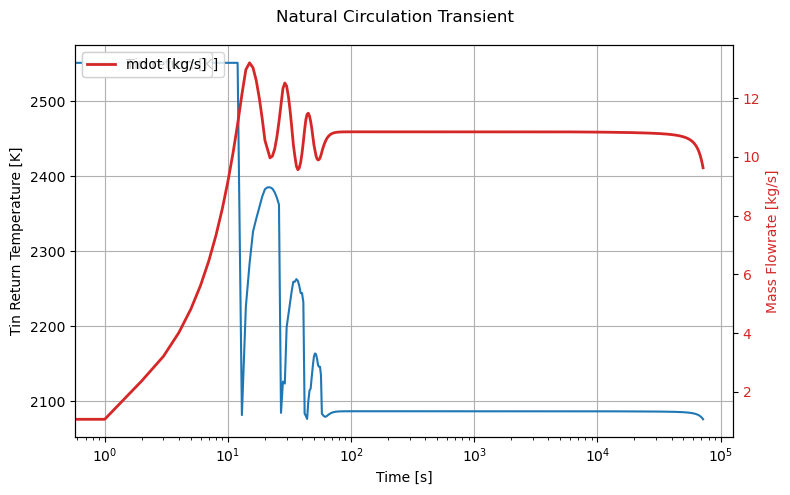

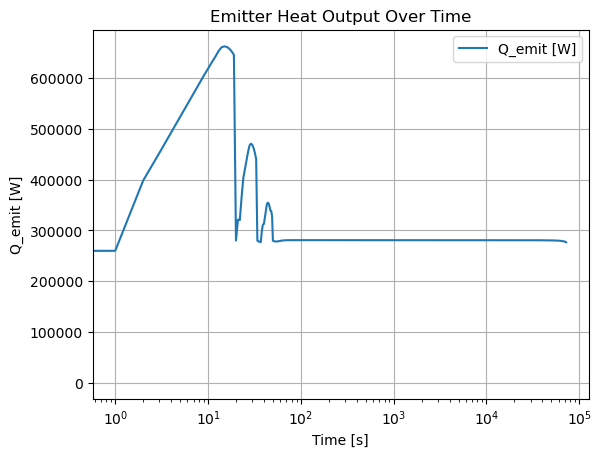

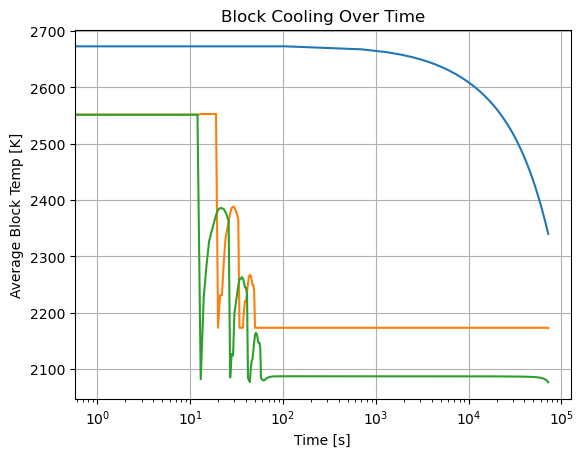

In [602]:
# --- Run Natural Circ Transient Simulation ---

# Setup system
sim = NaturalCircSystemSimulation(
    storage=storage_module,
    power_conversion=power_conversion,
    pipe_up=pipe_up,
    pipe_down=pipe_down,
    T_sur=300,                # ambient temperature [K] (adjust as relevant)
    dt_fast=1.0,              # short timestep during startup [s]
    dt_slow=600.0,             # long timestep during block cooling [s]
    N_down=1000,                 # downcomer discretization (higher=more accurate plug flow)
    transient_flag = transient_flag,
    bypass_flag = bypass_flag,
    T_max_emit = T_max_emit
)

# --- Initial parameters ---
#T_block_init = 2373.0        # K (initial block temp)
#H_system = 3.0               # m (vertical height)
#T_init_fluid = 2373.0        # K (initial fluid temp everywhere)
t_total = 72000               # s (total sim time)
t_insert = 0.0               # s (stick insertion time)

# Emissivity tables
emissivity_insert = [((0.1, 1.24), 0.0001, 0.0001, 0.0001), ((1.24, 20.0), 0.0001, 0.0001, 0.0001)]
emissivity_real = [((0.1, 1.24), 0.95, 0.05, 0.05), ((1.24, 20.0), 0.05, 0.05, 0.05)]

# --- Run simulation ---
results = sim.run_transient_simulation(
    T_block_init=T_block_init,
    H_system=H_system,
    emissivity_insert=emissivity_insert,
    emissivity_real=emissivity_real,
    T_init_fluid=T_init_fluid,
    t_total=t_total,
    t_insert=t_insert,
    steady_threshold=0.001,
    steady_check_window=20,
    print_outputs=True        # set False to suppress timestep-wise prints
)

# --- Plotting example ---

fig, ax1 = plt.subplots(figsize=(8, 5))

color1 = 'tab:blue'
ax1.semilogx(results['time'], results['Tin_return'], color=color1, label='Tin return [K]')
ax1.set_xlabel('Time [s]')
ax1.set_ylabel('Tin Return Temperature [K]')
ax1.legend(loc='upper left')
ax1.grid(True)

ax2 = ax1.twinx()
color2 = 'tab:red'
ax2.semilogx(results['time'], results['mdot'], color=color2, label='mdot [kg/s]', linewidth=2)
ax2.set_ylabel('Mass Flowrate [kg/s]', color=color2)
ax2.tick_params(axis='y', labelcolor=color2)
ax2.legend(loc='upper left')

fig.suptitle('Natural Circulation Transient')
fig.tight_layout()
plt.show()

plt.figure()
plt.semilogx(results['time'], results['Q_emit'], label='Q_emit [W]')
plt.xlabel('Time [s]')
plt.ylabel('Q_emit [W]')
plt.grid()
plt.title('Emitter Heat Output Over Time')
plt.legend()
plt.show()

# To analyze block cooling:
plt.figure()
avg_block_temp = [np.mean(B) for B in results['block_temp']]
plt.semilogx(results["time"], avg_block_temp, label='Avg Block Temp')
plt.semilogx(results["time"], results['T_emit_in'], label='Emitter Inlet Temp')
plt.semilogx(results["time"], results['Tin_return'], label='Tin Return Temp')
plt.xlabel("Time [s]")
plt.ylabel("Average Block Temp [K]")
plt.title("Block Cooling Over Time")
plt.grid()
plt.show()

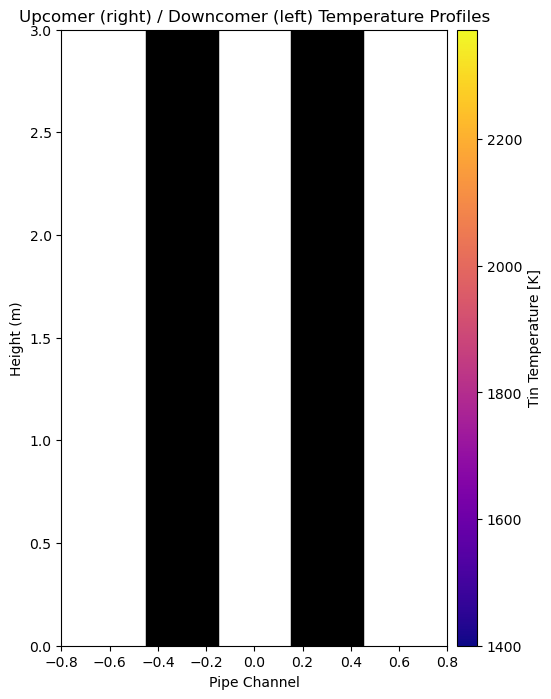


KeyboardInterrupt



In [472]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import numpy as np

upcomer_T_hist = results['upcomer_T_hist']  # shape (num_time_steps, N_segments)
downcomer_T_hist = results['downcomer_T_hist']  # shape (num_time_steps, N_segments)
N = upcomer_T_hist.shape[1]
H = H_system
dz = H / N
dt = results['dt'][0] if 'dt' in results else 1.0
time_arr = results['time']
mdot_arr = results['mdot']
num_frames = upcomer_T_hist.shape[0]

# --- Choose colormap range for your Tin (adjust as needed for your real system)
Tmin = min(upcomer_T_hist.min(), downcomer_T_hist.min(), 1400)
Tmax = max(upcomer_T_hist.max(), downcomer_T_hist.max(), T_block_init)

# --- Set up plot ---
fig, ax = plt.subplots(figsize=(6, 8))
y = np.linspace(0, H, N)

# Draw two vertical "pipes"
bar_width = 0.3
x_upcomer = np.full(N, -0.3)   # right of center
x_downcomer = np.full(N, 0.3) # left of center
bars_up = ax.barh(y, bar_width, left=x_upcomer - bar_width / 2, height=dz, color='gray', edgecolor='k')
bars_down = ax.barh(y, bar_width, left=x_downcomer - bar_width / 2, height=dz, color='gray', edgecolor='k')

ax.set_xlim(-0.8, 0.8)
ax.set_ylim(0, H)
ax.set_xlabel('Pipe Channel')
ax.set_ylabel('Height (m)')
ax.set_title(f'Upcomer (right) / Downcomer (left) Temperature Profiles')

sm = plt.cm.ScalarMappable(cmap='plasma', norm=plt.Normalize(vmin=Tmin, vmax=Tmax))
cbar = plt.colorbar(sm, ax=ax, orientation='vertical', pad=0.02, aspect=30)
cbar.set_label('Tin Temperature [K]')

def update(frame):
    T_up = upcomer_T_hist[frame]
    T_down = downcomer_T_hist[frame][::-1]
    for rect, T in zip(bars_up, T_up):
        rect.set_color(plt.cm.plasma((T - Tmin) / (Tmax - Tmin)))
    for rect, T in zip(bars_down, T_down):
        rect.set_color(plt.cm.plasma((T - Tmin) / (Tmax - Tmin)))
    t_label = time_arr[frame] if frame < len(time_arr) else frame * dt
    mdot_label = mdot_arr[frame] if frame < len(mdot_arr) else np.nan
    ax.set_title(f"Upcomer (left) / Downcomer (right)\nTime = {t_label:.1f} s   |   mdot = {mdot_label:.3f} kg/s")
    return list(bars_up) + list(bars_down)

ani = FuncAnimation(fig, update, frames=num_frames, interval=40, blit=False)
plt.show()

# Optionally save animation as mp4 or gif:
ani.save('circ_transient_bars.gif', writer='pillow')

In [418]:
def sweep_heat_transfer_vs_height(height_array, T_block_array, *args, **kwargs):
    Q_heat_matrix = np.zeros((len(T_block_array), len(height_array)))
    Q_elec_matrix = np.zeros((len(T_block_array), len(height_array)))
    mdot_matrix = np.zeros((len(T_block_array), len(height_array)))
    T_out_matrix = np.zeros((len(T_block_array), len(height_array)))
    for i_H, H in enumerate(height_array):
        for i_T, T in enumerate(T_block_array):
            results = solve_natural_circulation_steady_state(
                *args,
                **kwargs,
                H_system=H,
                T_block_init=T
            )
            Q_heat_matrix[i_T, i_H] = results["Q_emit_total"]
            Q_elec_matrix[i_T, i_H] = results["Q_elec"]
            mdot_matrix[i_T, i_H] = results["mdot_total"]
            T_out_matrix[i_T, i_H] = results["T_emit_out"]
    return Q_heat_matrix, mdot_matrix, T_out_matrix, Q_elec_matrix

# Example usage:
heights = np.linspace(2, 10, 5)  # meters
T_blocks = np.linspace(2073, 2673, 4) # K
Q_heat_matrix, mdot_matrix, T_out_matrix, Q_elec_matrix = sweep_heat_transfer_vs_height(
    heights,
    T_blocks,
    storage_module,
    power_conversion,
    pipe_up,
    pipe_down
)

plt.figure(figsize=(7,5))
for i, T_block in enumerate(T_blocks):
    plt.plot(heights, Q_heat_matrix[i], label=f"T_block={T_block:.0f} K", marker='o')

plt.xlabel("System Height (m)")
plt.ylabel("Total Heat Transfer to Powersticks (W)")
plt.title("Q_emit vs. System Height for Different Block Temperatures")
plt.legend(title="Block Temp")
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
for i, T_block in enumerate(T_blocks):
    plt.plot(heights, Q_elec_matrix[i], label=f"T_block={T_block:.0f} K", marker='o')

plt.xlabel("System Height (m)")
plt.ylabel("Electric Power (W)")
plt.title("Q_elec vs. System Height for Different Block Temperatures")
plt.legend(title="Block Temp")
plt.grid(True)
plt.tight_layout()
plt.show()

TypeError: solve_natural_circulation_steady_state() got an unexpected keyword argument 'T_block_init'

In [431]:
a=[1,2,3,4,5,6,7]
a[-3:]

[5, 6, 7]